# FarmTech Solutions — Fase 5: Machine Learning na Cabeça
## Entrega 1 — Análise exploratória, clusterização e regressão

**Grupo 7 — FIAP**  
**Kauan Maciel Forgiarini — RM574005:** implementação técnica.  
**Wagner Adriano de Souza Silva Junior — RM569431:** vídeos de apresentação.

## 1. Objetivo e origem dos dados

Analisar a base `crop_yield.csv` fornecida pela FIAP, explorar agrupamentos de condições
climáticas e comparar cinco algoritmos que preveem rendimento de safra.

O dataset original deve estar na mesma pasta deste notebook. Não são usados dados
sintéticos como substitutos. Execute todas as células, em ordem, para produzir os
resultados desta revisão. As saídas antigas foram removidas porque a metodologia mudou.

| Coluna | Significado segundo o enunciado |
|---|---|
| Crop | Cultura agrícola |
| Precipitation (mm day-1) | Precipitação em mm/dia |
| Specific Humidity at 2 Meters (g/kg) | Umidade específica |
| Relative Humidity at 2 Meters (%) | Umidade relativa |
| Temperature at 2 Meters (C) | Temperatura |
| Yield | Rendimento; o enunciado informa toneladas por hectare |

**Unidades:** os resultados serão mantidos na escala original do CSV. As magnitudes
observadas na versão anterior suscitam dúvida sobre as unidades de precipitação e
rendimento. Sem confirmação da fonte, não fazemos conversões nem interpretamos
literalmente essas magnitudes como medidas agronômicas verificadas.

## 2. Estratégia

Exploramos distribuições, correlações e outliers; segmentamos as condições climáticas
com K-Means; analisamos o rendimento por cluster e cultura; comparamos regressões com
pré-processamento dentro de pipelines. As associações encontradas não demonstram causalidade.

In [1]:
# Importação das bibliotecas necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


## 3. Análise Exploratória de Dados (EDA)

### 3.1 Carregamento e inspeção inicial

In [2]:
# Carregar somente a base original disponibilizada pela FIAP.
arquivo = Path('crop_yield.csv')
if not arquivo.is_file():
    raise FileNotFoundError('Adicione crop_yield.csv, original da FIAP, na pasta do notebook e execute novamente.')
df = pd.read_csv(arquivo)
colunas = ['Crop', 'Precipitation (mm day-1)', 'Specific Humidity at 2 Meters (g/kg)',
           'Relative Humidity at 2 Meters (%)', 'Temperature at 2 Meters (C)', 'Yield']
faltantes = set(colunas) - set(df.columns)
if faltantes:
    raise ValueError(f'Colunas ausentes no CSV: {sorted(faltantes)}')
if df[colunas].isna().any().any():
    raise ValueError('Há valores ausentes. Verifique a base e documente o tratamento antes de prosseguir.')
for nome in colunas[1:]:
    df[nome] = pd.to_numeric(df[nome], errors='raise')
if not np.isfinite(df[colunas[1:]].to_numpy()).all():
    raise ValueError('Há valores numéricos não finitos na base.')
print(f'Dimensões: {df.shape[0]} registros e {df.shape[1]} colunas')
display(df.head())

Dimensões: 156 registros e 6 colunas


,Crop,Precipitation (mm day-1),Specific Humidity at 2 Meters (g/kg),Relative Humidity at 2 Meters (%),Temperature at 2 Meters (C),Yield
0,"Cocoa, beans","2,248.9200",17.7200,83.4000,26.0100,11560
1,"Cocoa, beans","1,938.4200",17.5400,82.1100,26.1100,11253
2,"Cocoa, beans","2,301.5400",17.8100,82.7900,26.2400,9456
3,"Cocoa, beans","2,592.3500",17.6100,85.0700,25.5600,9321
4,"Cocoa, beans","2,344.7200",17.6100,84.1200,25.7600,8800


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 6 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Crop                                  156 non-null    object 
 1   Precipitation (mm day-1)              156 non-null    float64
 2   Specific Humidity at 2 Meters (g/kg)  156 non-null    float64
 3   Relative Humidity at 2 Meters (%)     156 non-null    float64
 4   Temperature at 2 Meters (C)           156 non-null    float64
 5   Yield                                 156 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 7.4+ KB


In [4]:
# Estatísticas descritivas gerais
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Precipitation (mm day-1),156.0000,"2,486.4990",289.4579,"1,934.6200","2,302.9900","2,424.5500","2,718.0800","3,085.7900"
Specific Humidity at 2 Meters (g/kg),156.0000,18.2031,0.2939,17.5400,18.0300,18.2700,18.4000,18.7000
Relative Humidity at 2 Meters (%),156.0000,84.7377,0.9962,82.1100,84.1200,84.8500,85.5100,86.1000
Temperature at 2 Meters (C),156.0000,26.1836,0.2610,25.5600,26.0200,26.1300,26.3000,26.8100
Yield,156.0000,"56,153.0962","70,421.9589","5,249.0000","8,327.7500","18,871.0000","67,518.7500","203,399.0000"


In [5]:
# Contagem de registros por cultura — dataset perfeitamente balanceado
df["Crop"].value_counts()

Crop
Cocoa, beans       39
Oil palm fruit     39
Rice, paddy        39
Rubber, natural    39
Name: count, dtype: int64

**Leitura da inspeção:** use as saídas acima para verificar tipos, número de registros
e distribuição das culturas. Quantidades iguais por cultura não garantem ausência de viés,
e a inexistência de nulos não comprova que a base passou por curadoria.

### 3.2 Distribuição do rendimento (Yield) por cultura

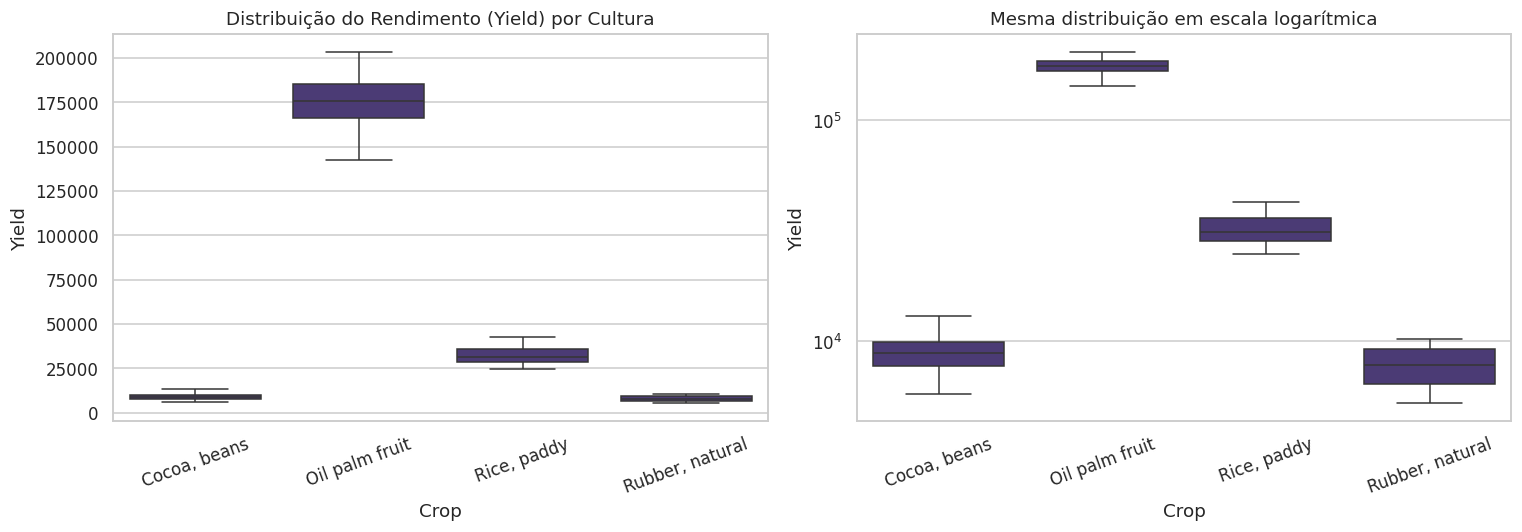

,mean,std,min,max
Crop,,,,
"Cocoa, beans","8,883.1282","1,745.0306","5,765.0000","13,056.0000"
Oil palm fruit,"175,804.6923","14,919.8698","142,425.0000","203,399.0000"
"Rice, paddy","32,099.6667","4,789.9484","24,686.0000","42,550.0000"
"Rubber, natural","7,824.8974","1,600.2550","5,249.0000","10,285.0000"


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="Crop", y="Yield", ax=axes[0])
axes[0].set_title("Distribuição do Rendimento (Yield) por Cultura")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Yield")

sns.boxplot(data=df, x="Crop", y="Yield", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Mesma distribuição em escala logarítmica")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

df.groupby("Crop")["Yield"].describe()[["mean", "std", "min", "max"]]

**Interpretação:** compare médias e dispersões dentro de cada cultura. Diferenças
de escala entre culturas podem dominar o R² global. Por isso, `Crop` participa da
regressão e uma baseline baseada apenas na média de cada cultura será avaliada.
Não é possível concluir que as unidades estão corretas apenas observando os boxplots.

### 3.3 Relação entre variáveis climáticas e rendimento

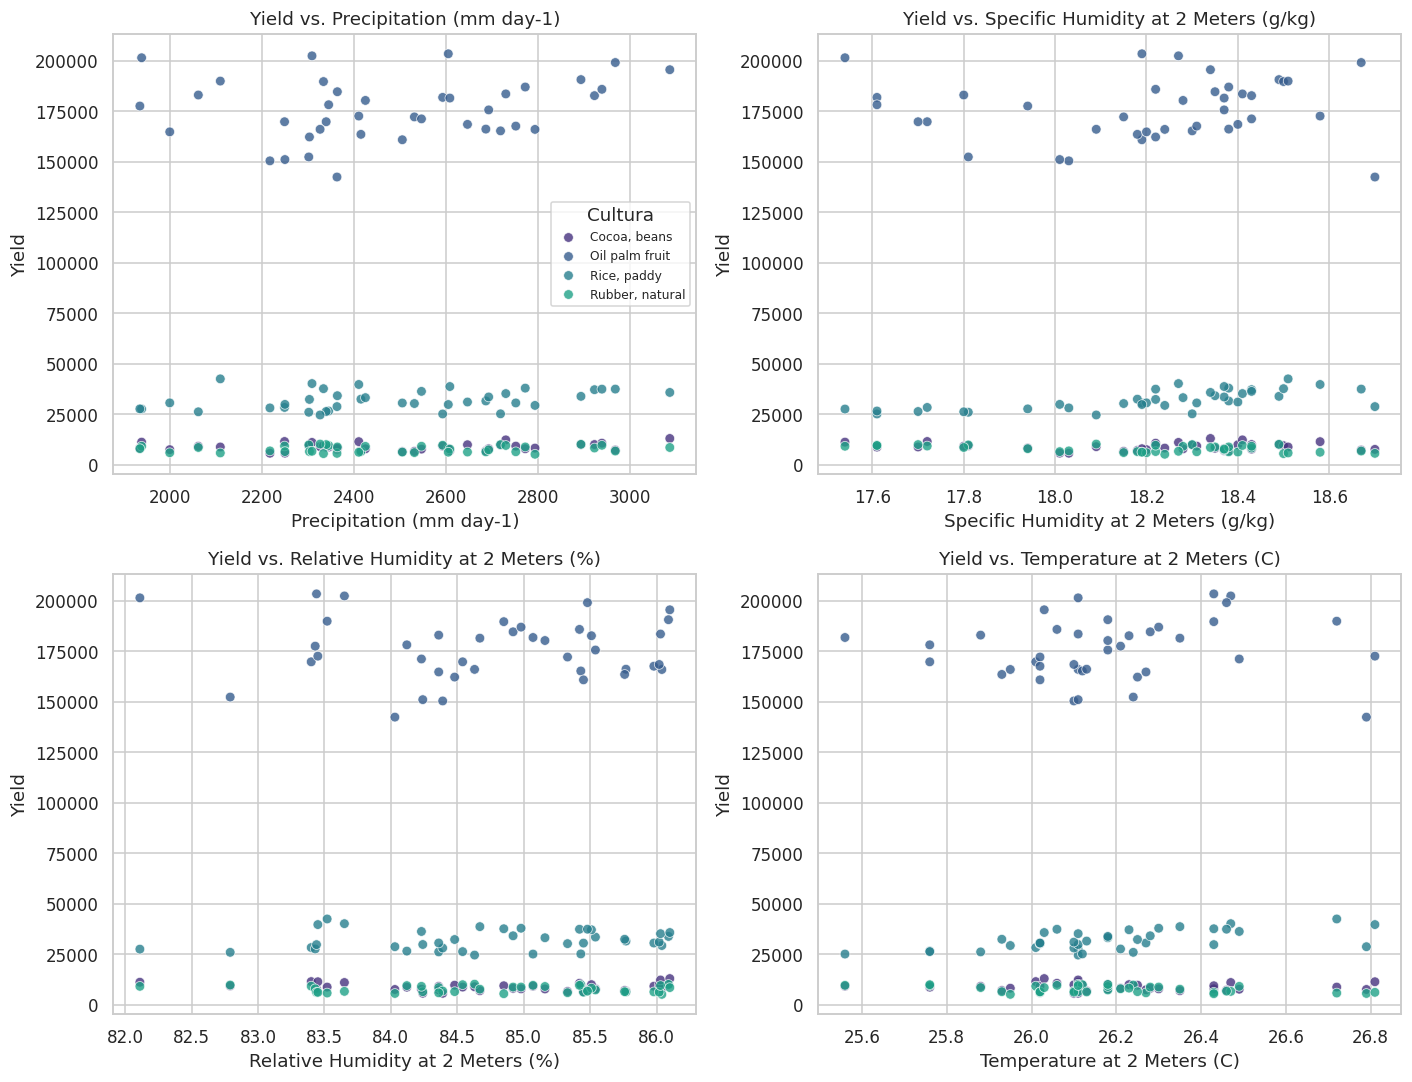

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
features = ["Precipitation (mm day-1)", "Specific Humidity at 2 Meters (g/kg)",
            "Relative Humidity at 2 Meters (%)", "Temperature at 2 Meters (C)"]

for ax, feat in zip(axes.ravel(), features):
    sns.scatterplot(data=df, x=feat, y="Yield", hue="Crop", ax=ax, s=40, alpha=0.8, legend=(feat == features[0]))
    ax.set_title(f"Yield vs. {feat}")

if axes.ravel()[0].get_legend() is not None:
    axes.ravel()[0].legend(fontsize=8, title="Cultura")

plt.tight_layout()
plt.show()

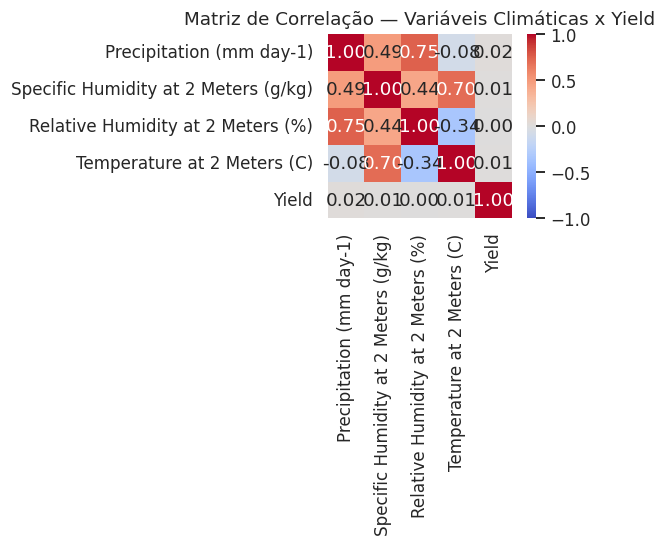

Yield                                  1.0000
Precipitation (mm day-1)               0.0188
Temperature at 2 Meters (C)            0.0130
Specific Humidity at 2 Meters (g/kg)   0.0127
Relative Humidity at 2 Meters (%)      0.0000
Name: Yield, dtype: float64

In [8]:
# Matriz de correlação (variáveis numéricas)
corr = df.drop(columns=["Crop"]).corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de Correlação — Variáveis Climáticas x Yield")
plt.tight_layout()
plt.show()
corr["Yield"].sort_values(ascending=False)

**Interpretação das correlações:** a correlação global pode esconder diferenças entre
culturas. A tabela abaixo calcula a correlação de cada variável climática com `Yield`
separadamente por cultura. Correlação fraca não prova ausência de relações não lineares;
correlação forte também não demonstra causalidade.

In [9]:
correlacoes_por_cultura = pd.DataFrame({
    cultura: grupo[features + ['Yield']].corr()['Yield'].drop('Yield')
    for cultura, grupo in df.groupby('Crop')
}).T
display(correlacoes_por_cultura.round(4))

,Precipitation (mm day-1),Specific Humidity at 2 Meters (g/kg),Relative Humidity at 2 Meters (%),Temperature at 2 Meters (C)
"Cocoa, beans",0.1736,-0.0550,-0.0582,-0.0098
Oil palm fruit,0.2223,0.0705,-0.0354,0.0972
"Rice, paddy",0.3286,0.6967,0.1498,0.6089
"Rubber, natural",0.1014,-0.4341,-0.0539,-0.4065


### Achados da análise exploratória

A base real possui **156 registros e 6 colunas**, sem valores ausentes, com **39 observações para cada uma das quatro culturas**. O rendimento apresenta escalas muito diferentes entre as culturas, principalmente para *Oil palm fruit*, portanto o **R² global deve ser interpretado com cautela**: parte importante da previsibilidade vem da própria variável `Crop`.

As correlações globais entre as variáveis climáticas e `Yield` são próximas de zero, mas isso esconde comportamentos específicos. Separando por cultura, os sinais mais fortes foram observados em **Rice, paddy**, com correlação de aproximadamente **0,6967** entre umidade específica e rendimento e **0,6089** entre temperatura e rendimento. Em **Rubber, natural**, umidade específica (**-0,4341**) e temperatura (**-0,4065**) apresentaram correlação negativa moderada. Esses valores descrevem associações na amostra e não demonstram causalidade.


### 3.4 Detecção de outliers (cenários discrepantes)

In [10]:
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum(), lim_inf, lim_sup

print("Outliers de Yield por cultura (regra IQR 1.5x):\n")
for cultura, grupo in df.groupby("Crop"):
    n_out, li, ls = contar_outliers_iqr(grupo["Yield"])
    print(f"  {cultura:<18} -> {n_out} outlier(s)  |  faixa aceitável: [{li:,.0f}, {ls:,.0f}]")

Outliers de Yield por cultura (regra IQR 1.5x):

  Cocoa, beans       -> 0 outlier(s)  |  faixa aceitável: [4,446, 13,202]
  Oil palm fruit     -> 0 outlier(s)  |  faixa aceitável: [137,199, 214,049]
  Rice, paddy        -> 0 outlier(s)  |  faixa aceitável: [16,586, 47,806]
  Rubber, natural    -> 0 outlier(s)  |  faixa aceitável: [2,086, 13,584]


**Interpretação dos outliers univariados:** a contagem acima informa o número exato de
observações fora dos limites IQR de cada cultura. Zero ocorrências significa apenas que
nenhum registro foi sinalizado por essa regra. Não demonstra limpeza prévia nem exclui
anomalias multivariadas. Os registros não são removidos automaticamente.

## 4. Clusterização e Análise de Tendências

Nesta etapa aplicamos **aprendizado não supervisionado** sobre as variáveis climáticas (sem usar `Yield` ou `Crop`) para identificar agrupamentos naturais de condições ambientais e verificar se esses agrupamentos se alinham com padrões de produtividade.

### 4.1 Padronização das variáveis

In [11]:
features_clima = ["Precipitation (mm day-1)", "Specific Humidity at 2 Meters (g/kg)",
                   "Relative Humidity at 2 Meters (%)", "Temperature at 2 Meters (C)"]

X_clima = df[features_clima].copy()
scaler = StandardScaler()
X_clima_scaled = scaler.fit_transform(X_clima)
print("Variáveis climáticas padronizadas (média 0, desvio-padrão 1).")

Variáveis climáticas padronizadas (média 0, desvio-padrão 1).


### 4.2 Escolha do número ideal de clusters (Método do Cotovelo + Silhueta)

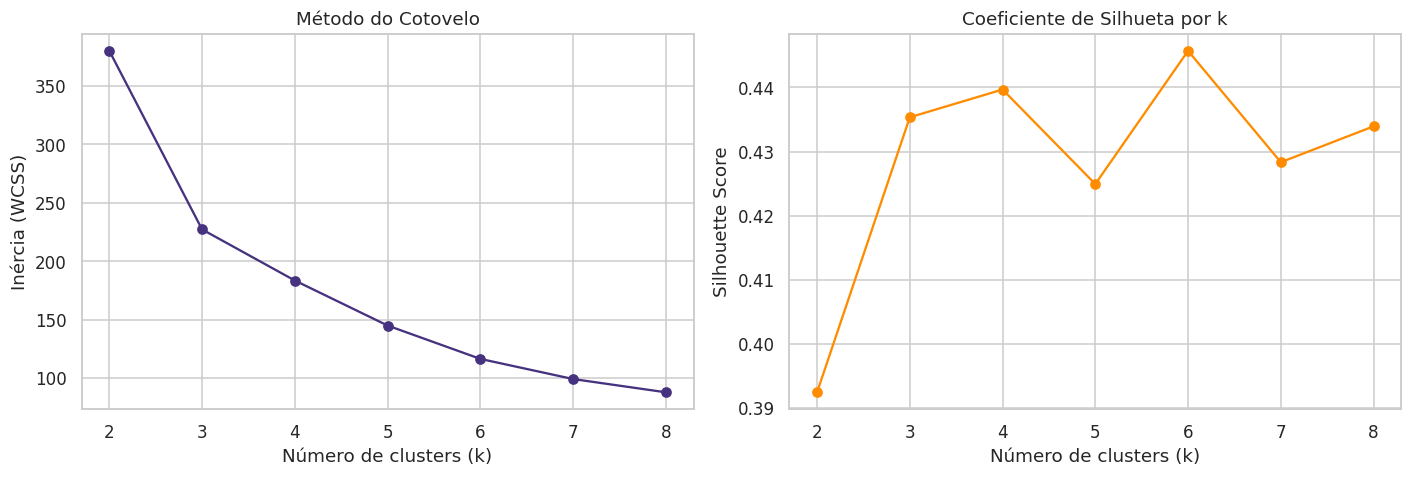

Melhor k pelo coeficiente de silhueta: k = 6 (score = 0.446)


In [12]:
inertias, silhouettes = [], []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_clima_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clima_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_title("Método do Cotovelo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inércia (WCSS)")

axes[1].plot(list(k_range), silhouettes, marker="o", color="darkorange")
axes[1].set_title("Coeficiente de Silhueta por k")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

melhor_k = list(k_range)[int(np.argmax(silhouettes))]
print(f"Melhor k pelo coeficiente de silhueta: k = {melhor_k} (score = {max(silhouettes):.3f})")

### 4.3 Aplicação do K-Means e visualização via PCA

Variância explicada pelas 2 componentes principais: 93.4%


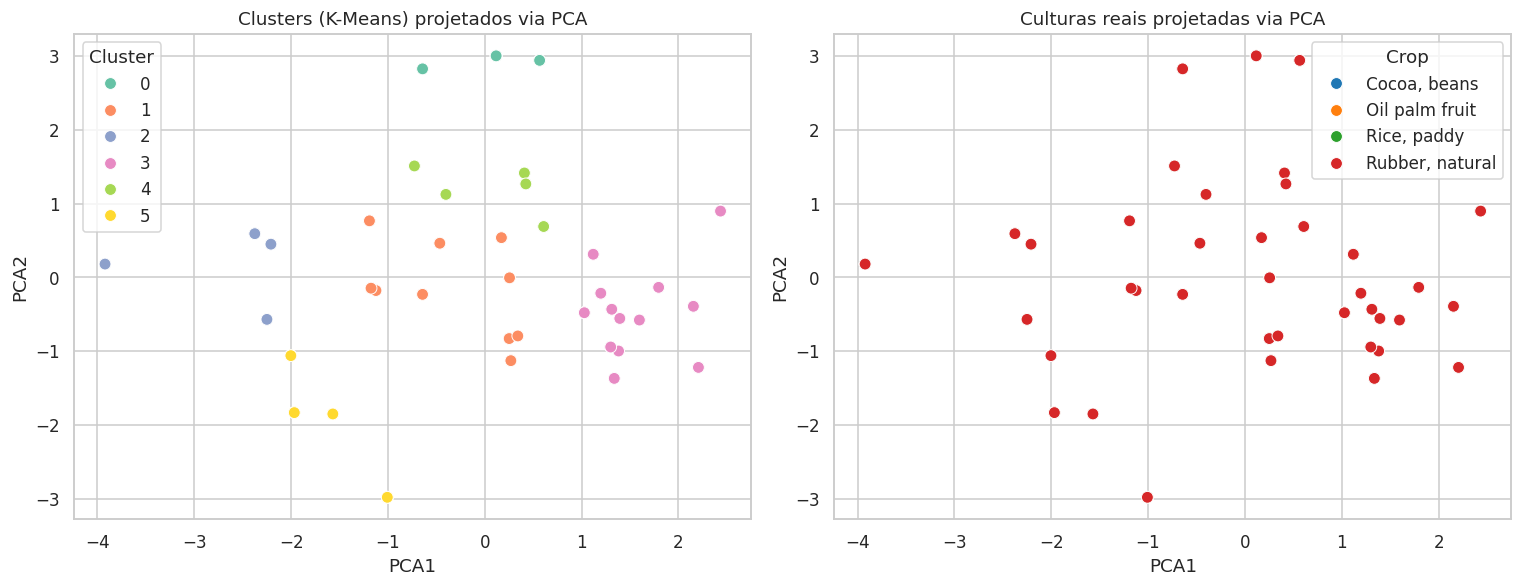

In [13]:
k_final = melhor_k  # maior silhueta entre os valores de k avaliados; não depende do número de culturas
kmeans = KMeans(n_clusters=k_final, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_clima_scaled)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_clima_scaled)
df["PCA1"], df["PCA2"] = X_pca[:, 0], X_pca[:, 1]

print(f"Variância explicada pelas 2 componentes principais: {pca.explained_variance_ratio_.sum()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Cluster", palette="Set2", s=60, ax=axes[0])
axes[0].set_title("Clusters (K-Means) projetados via PCA")

sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Crop", palette="tab10", s=60, ax=axes[1])
axes[1].set_title("Culturas reais projetadas via PCA")

plt.tight_layout()
plt.show()

In [14]:
# Tabela cruzada: cluster (não supervisionado) x cultura real
pd.crosstab(df["Cluster"], df["Crop"])

Crop,"Cocoa, beans",Oil palm fruit,"Rice, paddy","Rubber, natural"
Cluster,,,,
0,3,3,3,3
1,10,10,10,10
2,4,4,4,4
3,13,13,13,13
4,5,5,5,5
5,4,4,4,4


**Interpretação dos agrupamentos:** a tabela cruzada mostra a distribuição das culturas
por cluster. Os grupos foram definidos somente por condições climáticas e não devem
ser interpretados automaticamente como tipos de cultura. Repetições de uma mesma
combinação climática em culturas diferentes são verificadas na preparação da regressão.

### 4.4 Rendimento por cluster e cultura

As próximas tabelas e figuras comparam a produtividade na escala original dentro de
cada cultura, evitando confundir a diferença entre culturas com um efeito climático.
Contagens pequenas e dispersão elevada limitam a interpretação das médias.

quantidade        media      mediana  desvio_padrao
Crop            Cluster                                                     
Cocoa, beans    0                 3   9,332.6667   8,848.0000     1,957.5291
                1                10   7,438.6000   7,331.5000     1,326.8415
                2                 4  10,142.2500  10,354.5000     1,539.3294
                3                13   9,527.3077   9,880.0000     1,847.8204
                4                 5   8,692.4000   7,991.0000     1,615.0109
                5                 4   9,043.0000   9,025.5000       257.2586
Oil palm fruit  0                 3 168,307.3333 172,601.0000    24,025.0003
                1                10 165,607.2000 164,156.5000    11,066.1518
                2                 4 175,276.2500 173,663.0000    20,376.2969
                3                13 179,490.0000 182,696.0000    11,997.6776
                4                 5 189,624.0000 189,657.0000    13,769.1262
                5                 4 178,198.5000 180,004.5000     5,975.1188
Rice, paddy     0                 3  37,051.3333  39,775.0000     7,254.6696
                1                10  30,679.6000  30,645.0000     2,755.4851
                2                 4  27,440.7500  27,656.5000       998.7854
                3                13  33,598.6923  33,907.0000     3,833.0569
                4                 5  36,581.2000  37,704.0000     4,017.8941
                5                 4  26,121.2500  26,325.0000       644.0157
Rubber, natural 0                 3   5,948.0000   5,903.0000       280.2231
                1                10   7,331.7000   6,579.5000     1,511.5689
                2                 4   9,103.2500   9,272.5000       786.7085
                3                13   8,006.8462   8,337.0000     1,634.9711
                4                 5   7,117.8000   6,721.0000     1,423.5200
                5                 4   9,479.7500   9,645.5000       613.3527

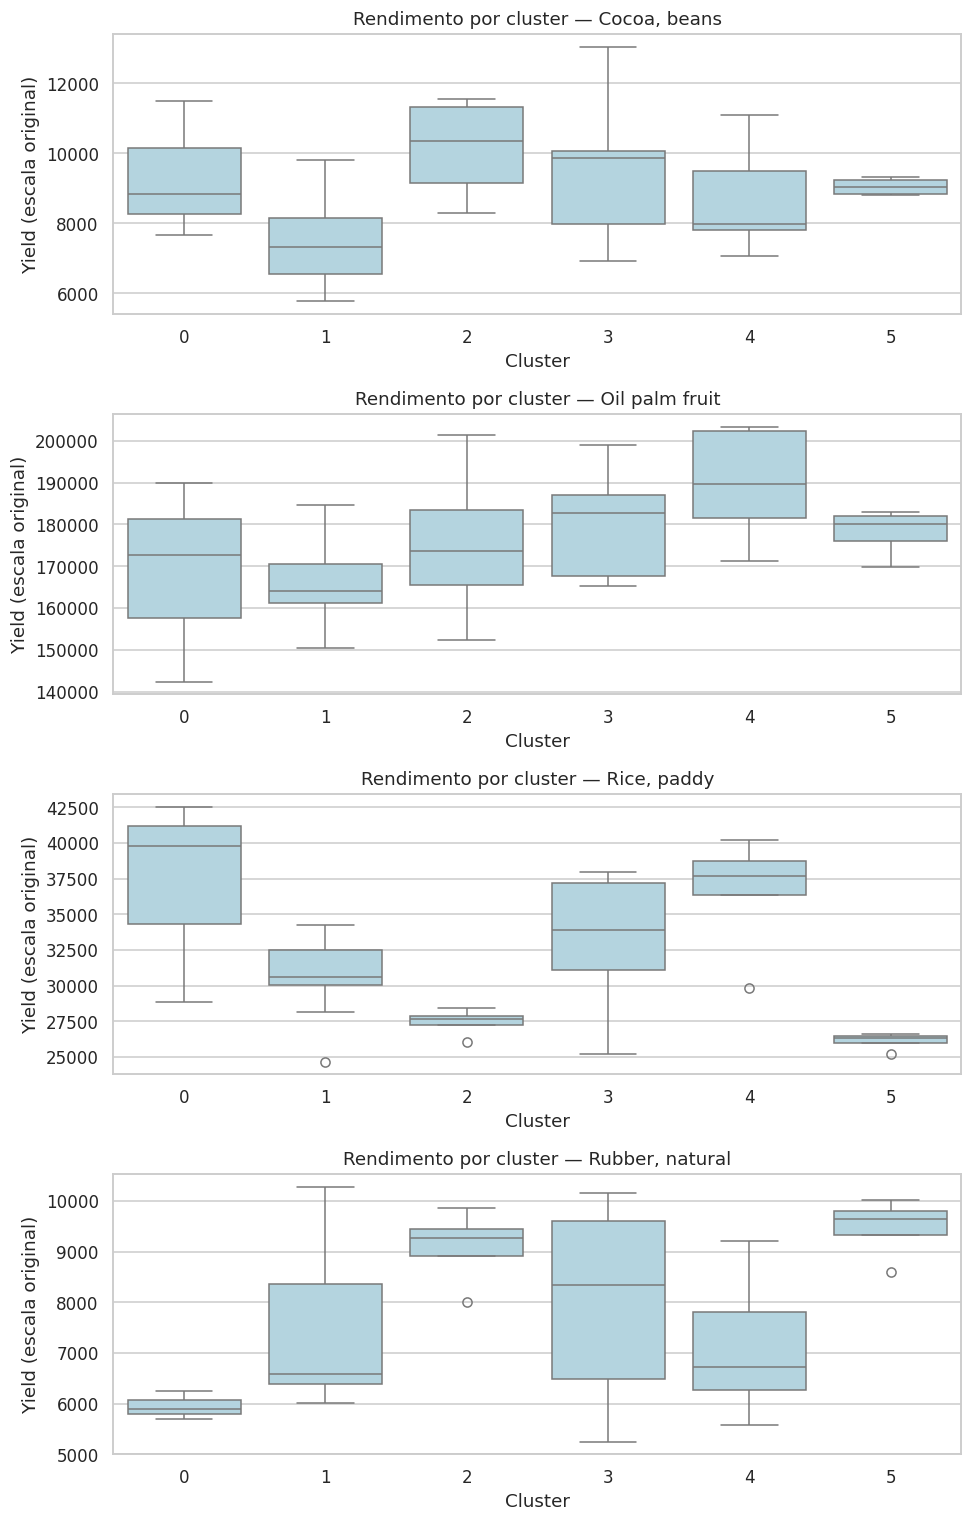

**Tendências descritivas por cultura:**

- **Cocoa, beans:** maior média observada no cluster 2 (10142.25; n=4); menor no cluster 1 (7438.60).
- **Oil palm fruit:** maior média observada no cluster 4 (189624.00; n=5); menor no cluster 1 (165607.20).
- **Rice, paddy:** maior média observada no cluster 0 (37051.33; n=3); menor no cluster 5 (26121.25).
- **Rubber, natural:** maior média observada no cluster 5 (9479.75; n=4); menor no cluster 0 (5948.00).

Essas diferenças são associações nesta amostra, não efeitos causais nem diferenças estatisticamente comprovadas.

In [15]:
resumo_clusters = df.groupby(['Crop', 'Cluster'])['Yield'].agg(
    quantidade='count', media='mean', mediana='median', desvio_padrao='std')
display(resumo_clusters)
culturas = sorted(df['Crop'].unique())
fig, axes = plt.subplots(len(culturas), 1, figsize=(9, 3.5 * len(culturas)), squeeze=False)
for ax, cultura in zip(axes.ravel(), culturas):
    sns.boxplot(data=df[df['Crop'] == cultura], x='Cluster', y='Yield', ax=ax, color='lightblue')
    ax.set_title(f'Rendimento por cluster — {cultura}')
    ax.set_ylabel('Yield (escala original)')
plt.tight_layout()
plt.show()
textos = []
for cultura in culturas:
    tabela = resumo_clusters.loc[cultura]
    maior = tabela['media'].idxmax()
    menor = tabela['media'].idxmin()
    textos.append(f'- **{cultura}:** maior média observada no cluster {maior} '
                  f'({tabela.loc[maior, "media"]:.2f}; n={int(tabela.loc[maior, "quantidade"])}); '
                  f'menor no cluster {menor} ({tabela.loc[menor, "media"]:.2f}).')
display(Markdown('**Tendências descritivas por cultura:**\n\n' + '\n'.join(textos) +
    '\n\nEssas diferenças são associações nesta amostra, não efeitos causais nem diferenças estatisticamente comprovadas.'))

### O próximo bloco usa a distância ao centroide para sinalizar possíveis anomalias.

In [16]:
df["dist_centroide"] = np.linalg.norm(
    X_clima_scaled - kmeans.cluster_centers_[df["Cluster"].values], axis=1
)

limiar = df["dist_centroide"].mean() + 2 * df["dist_centroide"].std()
outliers_multivariados = df[df["dist_centroide"] > limiar]

print(f"Limiar de distância (média + 2 desvios-padrão): {limiar:.2f}")
print(f"Registros identificados como outliers multivariados: {len(outliers_multivariados)}\n")
outliers_multivariados[["Crop", "Precipitation (mm day-1)", "Temperature at 2 Meters (C)", "Yield", "Cluster"]]

Limiar de distância (média + 2 desvios-padrão): 1.44
Registros identificados como outliers multivariados: 4



,Crop,Precipitation (mm day-1),Temperature at 2 Meters (C),Yield,Cluster
36,"Cocoa, beans","2,967.4100",26.4600,7314,3
75,Oil palm fruit,"2,967.4100",26.4600,199074,3
114,"Rice, paddy","2,967.4100",26.4600,37496,3
153,"Rubber, natural","2,967.4100",26.4600,6842,3


### Achados da clusterização e dos cenários discrepantes

O melhor resultado de silhueta entre `k=2` e `k=8` ocorreu em **k = 6**, com coeficiente de aproximadamente **0,4457**. As duas componentes principais usadas apenas para visualização preservam cerca de **93,4% da variância** das variáveis climáticas padronizadas.

Como as mesmas **39 combinações climáticas aparecem uma vez para cada cultura**, cada cluster contém as quatro culturas em proporções iguais. Portanto, os clusters representam **tipos de condição climática**, e não tipos de cultura. A tendência de rendimento deve ser comparada **dentro de cada cultura**, evitando atribuir à condição climática diferenças que são principalmente de escala entre culturas.

A regra de distância ao centroide sinalizou **4 registros multivariados**. Eles correspondem à **mesma combinação climática** repetida nas quatro culturas (precipitação 2967,41; umidade específica 18,67; umidade relativa 85,48; temperatura 26,46 °C). Assim, o cenário é atípico no espaço climático, mas isso não significa, por si só, erro de medição ou evento agronômico extremo.


**Interpretação dos outliers multivariados:** registros cuja distância excede a média
mais dois desvios são candidatos à inspeção. Esse limiar é uma heurística exploratória,
não um diagnóstico de seca, onda de calor ou falha de sensor. As linhas sinalizadas
mostram quais combinações foram identificadas; não são excluídas do treinamento.

## 5. Modelagem supervisionada — cinco algoritmos
### 5.1 Separação e pré-processamento

`Yield` é o alvo; `Crop` e as quatro variáveis climáticas são as entradas. Para avaliar
generalização para condições climáticas não presentes no treino, observações com a mesma
combinação das quatro variáveis climáticas ficam no mesmo grupo. A separação treino/teste
e a validação cruzada respeitam esses grupos.

One-hot encoding e padronização são ajustados dentro de cada pipeline e de cada fold.
O conjunto de teste fica reservado para a avaliação final; a escolha do modelo usa
RMSE médio de validação cruzada, não o desempenho no teste.

In [17]:
X = df[['Crop'] + features_clima].copy()
y = df['Yield'].copy()
# Cada combinação climática exata recebe um identificador de grupo.
grupos = df.groupby(features_clima, sort=False).ngroup()
print(f'Combinações climáticas distintas: {grupos.nunique()} em {len(df)} registros')
separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
idx_treino, idx_teste = next(separador.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_treino], X.iloc[idx_teste]
y_train, y_test = y.iloc[idx_treino], y.iloc[idx_teste]
grupos_train = grupos.iloc[idx_treino]
assert set(grupos_train).isdisjoint(set(grupos.iloc[idx_teste]))
if grupos_train.nunique() < 5:
    raise ValueError('São necessários pelo menos cinco grupos climáticos no treino para esta validação.')
print(f'Treino: {len(X_train)} amostras | Teste: {len(X_test)} amostras no total')
display(pd.DataFrame({'Treino': X_train['Crop'].value_counts(),
                      'Teste': X_test['Crop'].value_counts()}).fillna(0).astype(int))
preprocessador = ColumnTransformer(transformers=[
    ('num', StandardScaler(), features_clima),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['Crop']),
])

Combinações climáticas distintas: 39 em 156 registros
Treino: 124 amostras | Teste: 32 amostras no total


,Treino,Teste
Crop,,
"Cocoa, beans",31,8
Oil palm fruit,31,8
"Rice, paddy",31,8
"Rubber, natural",31,8


### 5.2 Treinamento e comparação

Comparamos cinco algoritmos. Os hiperparâmetros abaixo são escolhas fixas sem busca
sistemática. A validação cruzada usa cinco folds agrupados por condições climáticas.
RMSE é a métrica principal de seleção; também reportamos MAE e R² no teste. O desvio
entre folds descreve variabilidade, não constitui teste de significância estatística.

In [18]:
modelos = {
    'Regressão Linear': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'SVR (RBF)': SVR(kernel='rbf', C=10000, epsilon=1000),
}
resultados = []
kf = GroupKFold(n_splits=5)
for nome, modelo in modelos.items():
    pipe = Pipeline([('prep', preprocessador), ('modelo', modelo)])
    # A transformação é reaprendida usando somente o treino de cada fold.
    cv_mse = -cross_val_score(pipe, X_train, y_train, groups=grupos_train,
                              cv=kf, scoring='neg_mean_squared_error')
    cv_rmse = np.sqrt(cv_mse)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    resultados.append({
        'Modelo': nome,
        'RMSE (CV médio, treino)': cv_rmse.mean(),
        'RMSE (CV desvio)': cv_rmse.std(ddof=1),
        'R² (teste)': r2_score(y_test, y_pred),
        'RMSE (teste)': np.sqrt(mean_squared_error(y_test, y_pred)),
        'MAE (teste)': mean_absolute_error(y_test, y_pred),
    })
df_resultados = pd.DataFrame(resultados).sort_values('RMSE (CV médio, treino)').reset_index(drop=True)
display(df_resultados.round(4))

,Modelo,"RMSE (CV médio, treino)",RMSE (CV desvio),R² (teste),RMSE (teste),MAE (teste)
0,Random Forest,"7,206.6261","2,098.0043",0.9820,"9,851.1457","5,849.4919"
1,Gradient Boosting,"7,600.5408","1,748.1034",0.9889,"7,724.8703","4,793.0451"
2,Regressão Linear,"8,127.7826","1,617.5058",0.9863,"8,601.4357","5,857.9796"
3,Ridge Regression,"8,493.6764","1,579.6002",0.9819,"9,889.7245","6,222.2952"
4,SVR (RBF),"60,042.0616","3,128.6900",0.3151,"60,815.3499","32,436.5368"


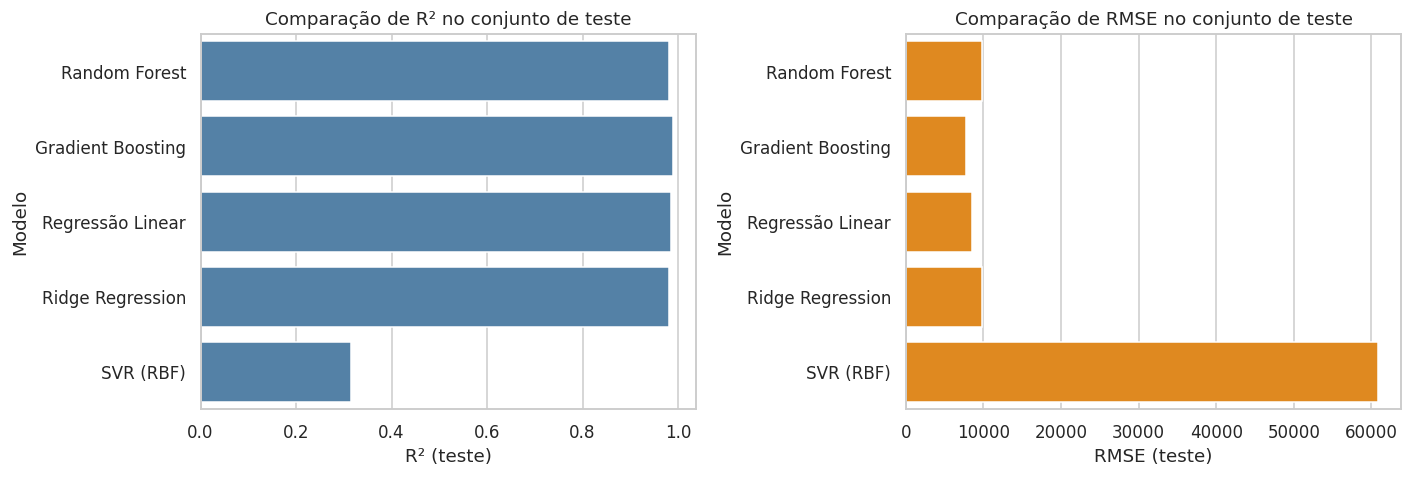

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df_resultados, x="R² (teste)", y="Modelo", ax=axes[0], color="steelblue")
axes[0].set_title("Comparação de R² no conjunto de teste")
# O eixo permite R² negativo caso algum modelo tenha desempenho ruim.

sns.barplot(data=df_resultados, x="RMSE (teste)", y="Modelo", ax=axes[1], color="darkorange")
axes[1].set_title("Comparação de RMSE no conjunto de teste")

plt.tight_layout()
plt.show()

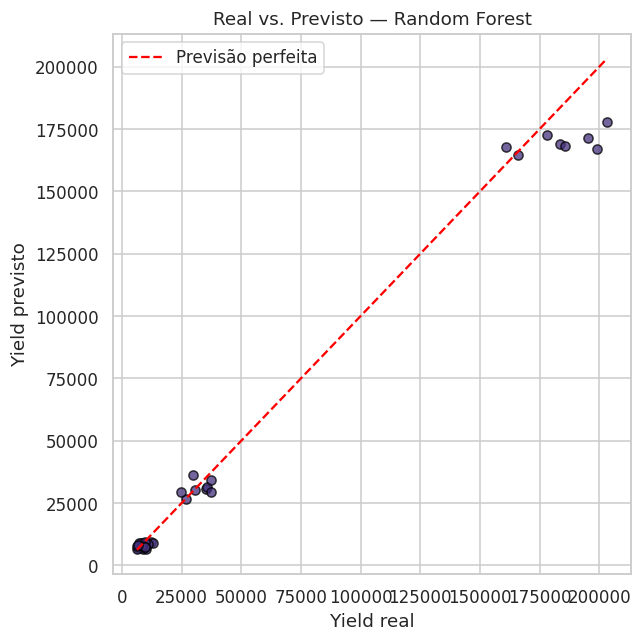

Modelo selecionado pela validação cruzada: Random Forest
Modelo                     Random Forest
RMSE (CV médio, treino)       7,206.6261
RMSE (CV desvio)              2,098.0043
R² (teste)                        0.9820
RMSE (teste)                  9,851.1457
MAE (teste)                   5,849.4919
Name: 0, dtype: object


In [20]:
# Modelo selecionado pelo menor RMSE de validação cruzada.
melhor_nome = df_resultados.iloc[0]["Modelo"]
melhor_modelo = Pipeline([("prep", preprocessador), ("modelo", modelos[melhor_nome])])
melhor_modelo.fit(X_train, y_train)
y_pred_melhor = melhor_modelo.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_melhor, alpha=0.75, edgecolor="k")
lims = [min(y_test.min(), y_pred_melhor.min()), max(y_test.max(), y_pred_melhor.max())]
plt.plot(lims, lims, "r--", label="Previsão perfeita")
plt.xlabel("Yield real")
plt.ylabel("Yield previsto")
plt.title(f"Real vs. Previsto — {melhor_nome}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Modelo selecionado pela validação cruzada: {melhor_nome}")
print(df_resultados.iloc[0])

### 5.3 Discussão dos resultados

O resumo calculado abaixo identifica o modelo selecionado, suas métricas e a comparação
com uma baseline que prevê a média de `Yield` da cultura usando apenas o treino.
Essa referência permite avaliar se o clima acrescenta desempenho além da identificação
da cultura. O R² global deve ser lido junto às métricas por cultura: diferenças grandes
de escala podem produzir um R² global alto mesmo com erros relevantes em um subgrupo.

Valores próximos não comprovam equivalência estatística. O SVR utiliza `C=10000` e
`epsilon=1000`, sem tuning; seu desempenho se refere a essa configuração específica.
O teste compara os modelos, mas não é usado para alterar a escolha feita pela validação.

In [21]:
# Baseline ajustada apenas com dados de treino.
media_por_cultura = pd.DataFrame({'Crop': X_train['Crop'], 'Yield': y_train}).groupby('Crop')['Yield'].mean()
pred_baseline = X_test['Crop'].map(media_por_cultura).fillna(y_train.mean())
rmse_base = np.sqrt(mean_squared_error(y_test, pred_baseline))
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_melhor))
avaliacao = X_test[['Crop']].copy()
avaliacao['real'] = y_test
avaliacao['previsto'] = y_pred_melhor
avaliacao['baseline'] = pred_baseline
linhas = []
for cultura, g in avaliacao.groupby('Crop'):
    linhas.append({'Cultura': cultura, 'n_teste': len(g),
        'RMSE modelo': np.sqrt(mean_squared_error(g['real'], g['previsto'])),
        'MAE modelo': mean_absolute_error(g['real'], g['previsto']),
        'RMSE baseline': np.sqrt(mean_squared_error(g['real'], g['baseline']))})
display(pd.DataFrame(linhas).round(4))
display(Markdown(
    f'**Síntese calculada:** entre os cinco algoritmos avaliados, **{melhor_nome}** '
    f'foi selecionado pelo menor RMSE médio na validação cruzada. No teste com '
    f'**{len(y_test)} amostras no total**, apresentou R² de '
    f'**{r2_score(y_test, y_pred_melhor):.4f}**, RMSE de **{rmse_final:.4f}** e '
    f'MAE de **{mean_absolute_error(y_test, y_pred_melhor):.4f}**. '
    f'A baseline por cultura apresentou RMSE de **{rmse_base:.4f}**. '
    f'O modelo teve RMSE {"menor" if rmse_final < rmse_base else "maior ou igual"} '
    'ao da baseline nesta divisão. Os erros estão na escala original de Yield; '
    'essa comparação isolada não comprova significância estatística.'))

,Cultura,n_teste,RMSE modelo,MAE modelo,RMSE baseline
0,"Cocoa, beans",8,"2,247.3660","1,926.6800","2,329.0841"
1,Oil palm fruit,8,"18,901.7040","15,961.9500","17,656.0319"
2,"Rice, paddy",8,"4,727.0258","3,988.1042","4,663.8140"
3,"Rubber, natural",8,"1,873.6185","1,521.2333","1,716.4652"


**Síntese calculada:** entre os cinco algoritmos avaliados, **Random Forest** foi selecionado pelo menor RMSE médio na validação cruzada. No teste com **32 amostras no total**, apresentou R² de **0.9820**, RMSE de **9851.1457** e MAE de **5849.4919**. A baseline por cultura apresentou RMSE de **9244.6945**. O modelo teve RMSE maior ou igual ao da baseline nesta divisão. Os erros estão na escala original de Yield; essa comparação isolada não comprova significância estatística.

### Achados dos modelos preditivos

Pela validação cruzada agrupada por combinações climáticas, o **Random Forest** apresentou o menor RMSE médio (**≈ 7.206,63**) e foi selecionado sem consultar o conjunto de teste. No teste reservado de **32 amostras**, o modelo obteve **R² = 0,9820**, **RMSE ≈ 9.851,15** e **MAE ≈ 5.849,49**.

Apesar do R² global elevado, a **baseline que prevê a média de rendimento de cada cultura** obteve RMSE global de **≈ 9.244,69**, ligeiramente melhor que o Random Forest nessa divisão específica. Além disso, o modelo só superou a baseline em RMSE para *Cocoa, beans*; nas outras três culturas, a baseline foi igual ou melhor. Isso mostra que o R² global é influenciado pelas grandes diferenças de escala entre culturas e que, com esta base pequena, as variáveis climáticas ainda não demonstram ganho consistente sobre uma regra simples baseada apenas na cultura.

Entre os demais modelos, o **Gradient Boosting** teve RMSE de teste menor que o Random Forest, mas não foi escolhido porque a seleção foi feita corretamente **apenas pela validação cruzada do treino**, preservando o conjunto de teste para avaliação final. O resultado reforça a necessidade de mais dados e validação externa antes de uso em produção.


## 6. Conclusão, limites e próximos passos

O trabalho reúne inspeção dos dados, clusterização com escolha de k por silhueta,
identificação exploratória de anomalias e comparação de cinco regressores. As tabelas
e os resumos calculados acima devem fundamentar a leitura dos resultados desta execução.

### Pontos fortes
- Pré-processamento dentro dos pipelines e dos folds de validação.
- Separação por grupos climáticos, impedindo que a mesma combinação exata apareça nos dois conjuntos.
- Seleção do modelo pela validação cruzada e comparação com baseline por cultura.
- Análise de produtividade por cluster e por cultura, com contagens e dispersão.

### Limitações
- Base pequena: o número exato de amostras de treino e teste está na Seção 5.1.
- Agrupar condições climáticas exatas não elimina dependências temporais ou espaciais desconhecidas.
- Unidades do arquivo precisam de confirmação; não foram convertidas arbitrariamente.
- Apenas quatro variáveis climáticas e a cultura; outras condições de solo e manejo não estão disponíveis.
- Hiperparâmetros fixos, sem busca sistemática ou teste formal de equivalência.
- Outliers são candidatos exploratórios, não eventos agronômicos comprovados.
- Resultados de uma base acadêmica não demonstram desempenho em produção.

### Próximos passos
Confirmar unidades e origem dos registros, obter dados com safra e localização, validar
em novas condições, avaliar tuning somente no treino e estudar erros por cultura antes
de propor uso operacional. A Entrega 2 estima hospedagem; não representa um deploy realizado.